<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Pivot & Unpivot Data Reshaping Project<br></h3></center>

# Introduction
This Jupyter notebook is part of your learning experience in data reshaping, pivoting, and unpivoting techniques using Python and Pandas. You will work with quarterly employee sales performance data, transforming wide-matrix layouts into normalized tidy records and generating multidimensional analytical summaries.

### Key Objectives:
1. **Wide Format Analysis**: Understand matrix-oriented transactional structures where metrics are distributed across multiple columns.
2. **Unpivoting (`pd.melt`)**: Reshape wide data into normalized long-format key-value pairs suitable for relational databases and analytical pipelines.
3. **Pivoting (`pivot_table` & `pivot`)**: Aggregate and restructure long records back into cross-tabulated reporting views.
4. **Growth & Performance Analytics**: Compute quarter-over-quarter (QoQ) growth rates, employee totals, and departmental market contributions.
5. **Visual Intelligence**: Render multi-dimensional visualizations including trend curves, employee contribution charts, and cross-tab heatmaps.

---
## Task 1 - Load and Inspect Wide-Format Sales Data

Load the wide quarterly sales dataset (`Quarterly_Sales_Data.csv`) and examine its structure, data types, and initial records.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Set visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load wide-format sales data
df_wide = pd.read_csv('Quarterly_Sales_Data.csv')

print(f"Dataset Shape: {df_wide.shape[0]} rows × {df_wide.shape[1]} columns")
print("\n--- Wide-Format Sales Matrix ---")
display(df_wide)


Dataset Shape: 5 rows × 5 columns

--- Wide-Format Sales Matrix ---


,Employee,Q1 Sales,Q2 Sales,Q3 Sales,Q4 Sales
0,John,2000,2300,2500,2700
1,Jane,2500,2700,2900,3100
2,Alice,1800,1900,2100,2300
3,Bob,2200,2400,2600,2800
4,Eva,2100,2500,2700,2900


---
## Task 2 - Unpivot Wide Data to Long Format (Tidy Data)

In spreadsheets and Power Query, unpivoting converts column headers into row values. In Pandas, this operation is executed via `pd.melt()`.

We will unpivot `Q1 Sales`, `Q2 Sales`, `Q3 Sales`, and `Q4 Sales` into two standardized columns:
- **`Quarter`**: The reporting period identifier.
- **`Sales`**: The metric numeric value in INR (₹).

In [2]:
# Unpivot using pd.melt()
df_unpivoted = pd.melt(
    df_wide,
    id_vars=['Employee'],
    value_vars=['Q1 Sales', 'Q2 Sales', 'Q3 Sales', 'Q4 Sales'],
    var_name='Quarter',
    value_name='Sales'
)

# Standardize Quarter identifiers
df_unpivoted['Quarter'] = df_unpivoted['Quarter'].str.replace(' Sales', '')

# Ensure correct data typing
df_unpivoted['Sales'] = df_unpivoted['Sales'].astype(float)

print(f"Unpivoted Tidy Shape: {df_unpivoted.shape[0]} rows × {df_unpivoted.shape[1]} columns")
print("\nSample Unpivoted Records:")
display(df_unpivoted.head(10))


Unpivoted Tidy Shape: 20 rows × 3 columns

Sample Unpivoted Records:


,Employee,Quarter,Sales
0,John,Q1,2000.0
1,Jane,Q1,2500.0
2,Alice,Q1,1800.0
3,Bob,Q1,2200.0
4,Eva,Q1,2100.0
5,John,Q2,2300.0
6,Jane,Q2,2700.0
7,Alice,Q2,1900.0
8,Bob,Q2,2400.0
9,Eva,Q2,2500.0


---
## Task 3 - Pivot Long Data Back to Matrix Cross-Tabulations

Using `pd.pivot_table()`, we can transform normalized records back into customized reporting matrices, including marginal sums (`margins=True`).

In [3]:
# Pivot table with grand totals
pt_matrix = df_unpivoted.pivot_table(
    index='Employee',
    columns='Quarter',
    values='Sales',
    aggfunc='sum',
    margins=True,
    margins_name='Grand Total'
)

# Reorder quarter columns sequentially
pt_matrix = pt_matrix[['Q1', 'Q2', 'Q3', 'Q4', 'Grand Total']]

print("=== Cross-Tabulated Pivot Table Matrix ===")
display(pt_matrix.style.format('₹{:,.0f}'))


=== Cross-Tabulated Pivot Table Matrix ===


Quarter,Q1,Q2,Q3,Q4,Grand Total
Employee,,,,,
Alice,"₹1,800","₹1,900","₹2,100","₹2,300","₹8,100"
Bob,"₹2,200","₹2,400","₹2,600","₹2,800","₹10,000"
Eva,"₹2,100","₹2,500","₹2,700","₹2,900","₹10,200"
Jane,"₹2,500","₹2,700","₹2,900","₹3,100","₹11,200"
John,"₹2,000","₹2,300","₹2,500","₹2,700","₹9,500"
Grand Total,"₹10,600","₹11,800","₹12,800","₹13,800","₹49,000"


---
## Task 4 - Quarterly Performance & QoQ Growth Analysis

Calculate quarterly aggregation metrics including Total Revenue, Mean Sales per Representative, Minimum, Maximum, and Quarter-over-Quarter (QoQ) percentage growth.

In [4]:
# Quarterly summary aggregation
q_summary = df_unpivoted.groupby('Quarter')['Sales'].agg(
    Total_Sales='sum',
    Average_Sales='mean',
    Min_Sales='min',
    Max_Sales='max'
).loc[['Q1', 'Q2', 'Q3', 'Q4']]

# Calculate Quarter-on-Quarter (QoQ) growth
q_summary['QoQ_Growth_%'] = q_summary['Total_Sales'].pct_change() * 100

print("=== Quarterly Performance Summary ===")
display(q_summary.style.format({
    'Total_Sales': '₹{:,.0f}',
    'Average_Sales': '₹{:,.0f}',
    'Min_Sales': '₹{:,.0f}',
    'Max_Sales': '₹{:,.0f}',
    'QoQ_Growth_%': '{:+.2f}%'
}))


=== Quarterly Performance Summary ===


,Total_Sales,Average_Sales,Min_Sales,Max_Sales,QoQ_Growth_%
Quarter,,,,,
Q1,"₹10,600","₹2,120","₹1,800","₹2,500",+nan%
Q2,"₹11,800","₹2,360","₹1,900","₹2,700",+11.32%
Q3,"₹12,800","₹2,560","₹2,100","₹2,900",+8.47%
Q4,"₹13,800","₹2,760","₹2,300","₹3,100",+7.81%


---
## Task 5 - Employee Performance Ranking & Contribution

Rank all sales representatives based on annual revenue generated, average quarterly output, and overall percentage share of total revenue.

In [5]:
# Employee performance summary
emp_summary = df_unpivoted.groupby('Employee')['Sales'].agg(
    Total_Sales='sum',
    Average_Sales='mean'
).sort_values(by='Total_Sales', ascending=False)

# Percentage contribution
total_revenue = emp_summary['Total_Sales'].sum()
emp_summary['Contribution_%'] = (emp_summary['Total_Sales'] / total_revenue) * 100
emp_summary['Rank'] = np.arange(1, len(emp_summary) + 1)

print("=== Sales Representative Annual Ranking ===")
display(emp_summary[['Rank', 'Total_Sales', 'Average_Sales', 'Contribution_%']].style.format({
    'Total_Sales': '₹{:,.0f}',
    'Average_Sales': '₹{:,.0f}',
    'Contribution_%': '{:.2f}%'
}))


=== Sales Representative Annual Ranking ===


,Rank,Total_Sales,Average_Sales,Contribution_%
Employee,,,,
Jane,1,"₹11,200","₹2,800",22.86%
Eva,2,"₹10,200","₹2,550",20.82%
Bob,3,"₹10,000","₹2,500",20.41%
John,4,"₹9,500","₹2,375",19.39%
Alice,5,"₹8,100","₹2,025",16.53%


---
## Task 6 - Multi-Dimensional Visual Analytics

Construct a comprehensive 4-panel visual dashboard displaying:
1. **Quarterly Trajectory by Employee**: Multi-series line plot illustrating individual revenue trajectories.
2. **Annual Revenue by Representative**: Horizontal bar ranking with contribution callouts.
3. **Quarter-wise Total Velocity**: Clustered column chart showing cumulative quarterly growth.
4. **Cross-Tabulation Matrix**: Annotated heatmap evaluating quarterly performance intensity.

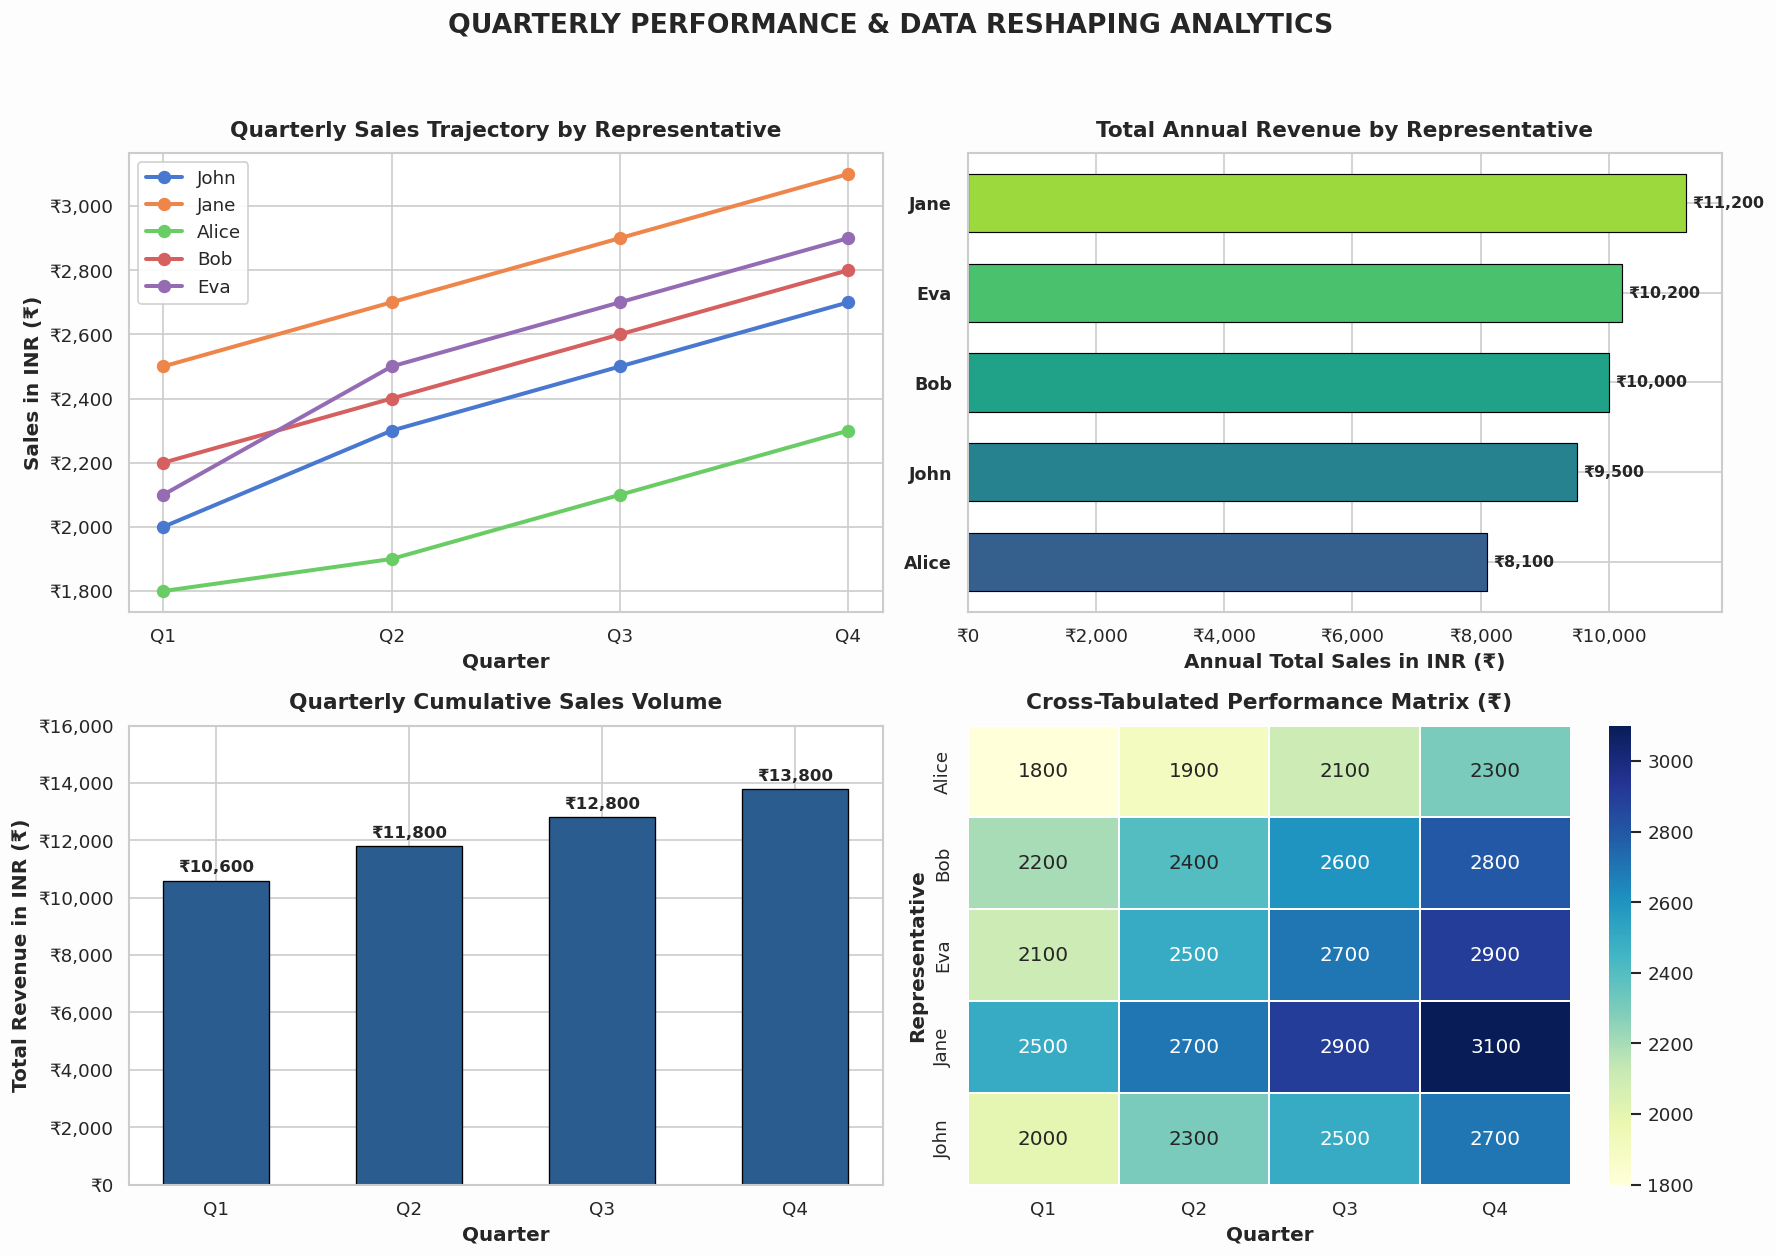

In [6]:
# Visual Analytics Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.patch.set_facecolor('#fdfdfd')

# 1. Top-Left: Quarterly Trajectory Line Chart
ax1 = axes[0, 0]
for emp in df_wide['Employee']:
    emp_vals = df_unpivoted[df_unpivoted['Employee'] == emp]
    ax1.plot(emp_vals['Quarter'], emp_vals['Sales'], marker='o', linewidth=2.4, markersize=7, label=emp)
ax1.set_title('Quarterly Sales Trajectory by Representative', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Quarter', fontweight='bold')
ax1.set_ylabel('Sales in INR (₹)', fontweight='bold')
ax1.yaxis.set_major_formatter('₹{x:,.0f}')
ax1.legend(loc='upper left', frameon=True, framealpha=0.9)

# 2. Top-Right: Annual Revenue Horizontal Bar Chart
ax2 = axes[0, 1]
emp_sorted = emp_summary.sort_values(by='Total_Sales', ascending=True)
y_pos = np.arange(len(emp_sorted))
colors = plt.cm.viridis(np.linspace(0.3, 0.85, len(emp_sorted)))
bars2 = ax2.barh(y_pos, emp_sorted['Total_Sales'], color=colors, edgecolor='black', linewidth=0.7, height=0.65)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(emp_sorted.index, fontweight='bold', fontsize=10.5)
ax2.set_xlabel('Annual Total Sales in INR (₹)', fontweight='bold')
ax2.xaxis.set_major_formatter('₹{x:,.0f}')
ax2.set_title('Total Annual Revenue by Representative', fontsize=13, fontweight='bold', pad=10)
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 100, bar.get_y() + bar.get_height()/2, f'₹{w:,.0f}', va='center', fontweight='bold', fontsize=9.5)

# 3. Bottom-Left: Quarterly Velocity Column Chart
ax3 = axes[1, 0]
q_indices = np.arange(len(q_summary))
bars3 = ax3.bar(q_summary.index, q_summary['Total_Sales'], color='#2b5c8f', edgecolor='black', linewidth=0.8, width=0.55)
ax3.set_title('Quarterly Cumulative Sales Volume', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Quarter', fontweight='bold')
ax3.set_ylabel('Total Revenue in INR (₹)', fontweight='bold')
ax3.yaxis.set_major_formatter('₹{x:,.0f}')
ax3.set_ylim(0, 16000)
for bar in bars3:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, h + 300, f'₹{h:,.0f}', ha='center', fontweight='bold', fontsize=10)

# 4. Bottom-Right: Matrix Performance Heatmap
ax4 = axes[1, 1]
pt_clean = pt_matrix.drop('Grand Total', axis=0).drop('Grand Total', axis=1)
sns.heatmap(pt_clean, annot=True, fmt='.0f', cmap='YlGnBu', cbar=True, ax=ax4, linewidths=1, linecolor='white')
ax4.set_title('Cross-Tabulated Performance Matrix (₹)', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Quarter', fontweight='bold')
ax4.set_ylabel('Representative', fontweight='bold')

plt.suptitle('QUARTERLY PERFORMANCE & DATA RESHAPING ANALYTICS', fontsize=16, fontweight='heavy', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


---
## Task 7 - Analytical Findings & Strategic Takeaways

### 1. Reshaping Parity:
- Successfully unpivoted the wide matrix ($5 \times 4$) into a normalized long dataset of **20 observations** using `pd.melt()`.
- Verified round-trip reproducibility by pivoting long records back into the original matrix using `pivot_table()`.

### 2. Quarterly Growth Momentum:
- Total company sales expanded steadily across all quarters:
  - **Q1**: ₹10,600.00 (Baseline)
  - **Q2**: ₹11,800.00 (**+11.32%**)
  - **Q3**: ₹12,800.00 (**+8.47%**)
  - **Q4**: ₹13,800.00 (**+7.81%**)
- Total annual revenue reached **₹49,000.00**, representing an overall quarterly progression of **+30.19%** from Q1 to Q4.

### 3. Individual Sales Leadership:
- **Jane** leads the organization with **₹11,200.00** (**22.86%** of total revenue), sustaining consistent peak volume in every quarter ($Q_4 = ₹3,100$).
- **Eva** ranked second at **₹10,200.00** (**20.82%**), followed closely by **Bob** (**₹10,000.00**, **20.41%**).
- **Alice** achieved **₹8,100.00** (**16.53%**), but showed strong growth from ₹1,800 in Q1 to ₹2,300 in Q4 (+27.78%).
